# **Lab 9 - Morphological Operations & Lab Tasks Solution**
---
- **Student Name:** Mujtaba Hajji Al-Nuwaisir 
- **Student ID:** 2240007941
- **Class** 7MA1

## **Part 1: Lab Walkthrough Examples**


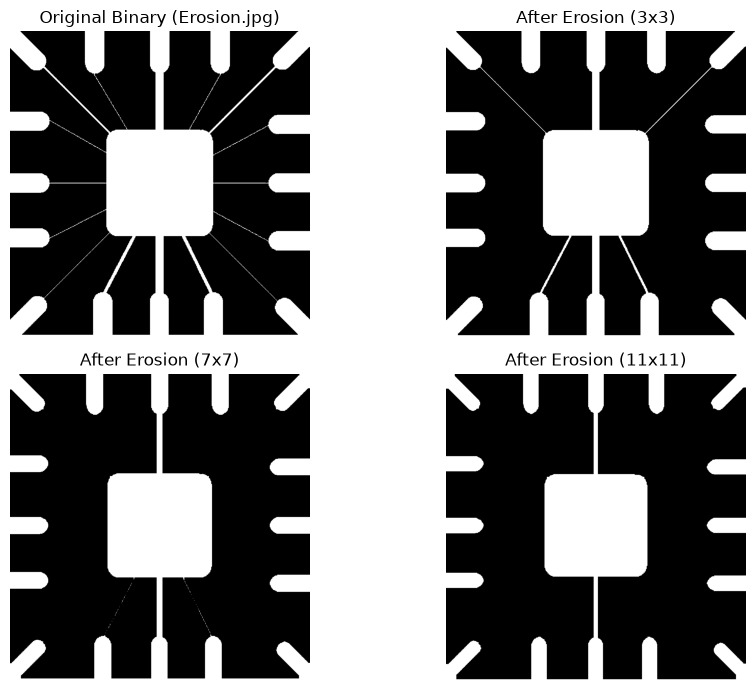

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load reference image and binarize using Otsu's thresholding
imgFile = 'Erosion.jpg'
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 2. Define square kernels of sizes 3x3, 7x7, and 11x11
kernel3 = np.ones((3, 3), np.uint8)
kernel7 = np.ones((7, 7), np.uint8)
kernel11 = np.ones((11, 11), np.uint8)

# 3. Apply Erosion
eroded_img3 = cv2.erode(binary, kernel3, iterations=1)
eroded_img7 = cv2.erode(binary, kernel7, iterations=1)
eroded_img11 = cv2.erode(binary, kernel11, iterations=1)

# 4. Display comparison
plt.figure(figsize=(10, 7))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary (Erosion.jpg)'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(eroded_img3, 'gray'), plt.title('After Erosion (3x3)'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(eroded_img7, 'gray'), plt.title('After Erosion (7x7)'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(eroded_img11, 'gray'), plt.title('After Erosion (11x11)'), plt.axis('off')
plt.tight_layout()
plt.show()

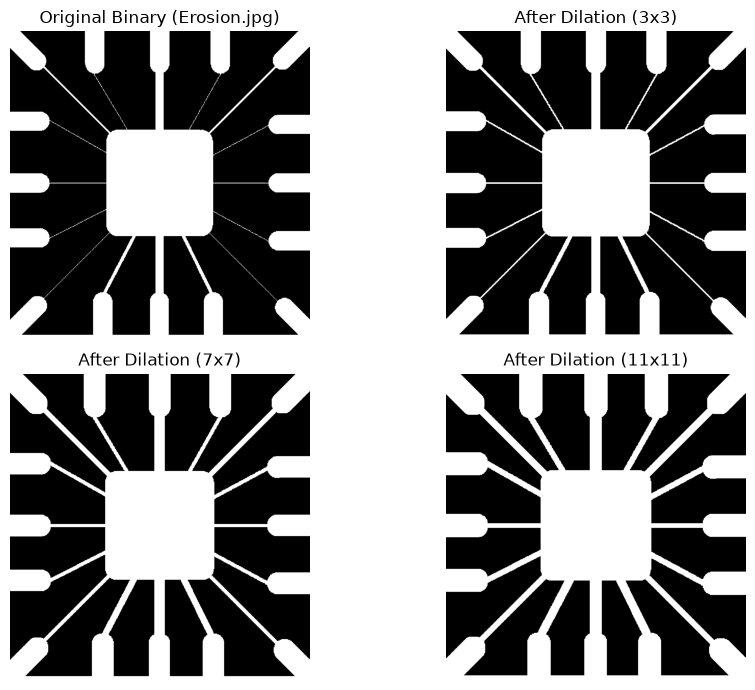

In [3]:
# Apply Dilation on Erosion.jpg using 3x3, 7x7, and 11x11 kernels
dilated_img3 = cv2.dilate(binary, kernel3, iterations=1)
dilated_img7 = cv2.dilate(binary, kernel7, iterations=1)
dilated_img11 = cv2.dilate(binary, kernel11, iterations=1)

plt.figure(figsize=(10, 7))
plt.subplot(2, 2, 1), plt.imshow(binary, 'gray'), plt.title('Original Binary (Erosion.jpg)'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(dilated_img3, 'gray'), plt.title('After Dilation (3x3)'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(dilated_img7, 'gray'), plt.title('After Dilation (7x7)'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(dilated_img11, 'gray'), plt.title('After Dilation (11x11)'), plt.axis('off')
plt.tight_layout()
plt.show()

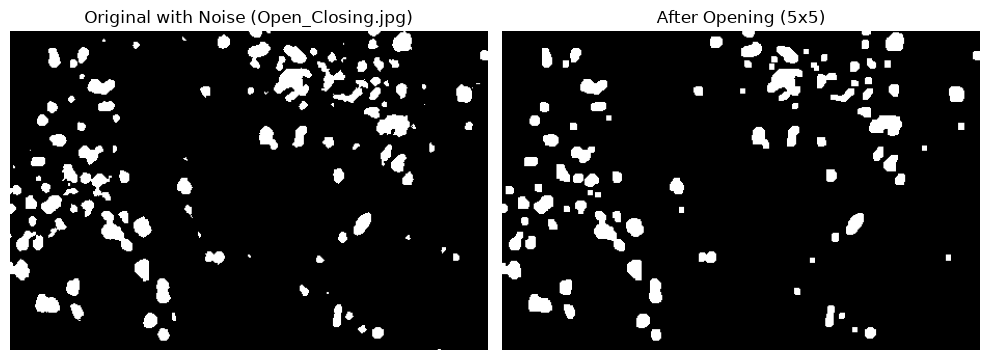

In [4]:
# Morphological Opening & Closing Examples
img_oc = cv2.imread('Open_Closing.jpg', 0)
_, bin_oc = cv2.threshold(img_oc, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
opening = cv2.morphologyEx(bin_oc, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1), plt.imshow(bin_oc, 'gray'), plt.title('Original with Noise (Open_Closing.jpg)'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(opening, 'gray'), plt.title('After Opening (5x5)'), plt.axis('off')
plt.tight_layout()
plt.show()

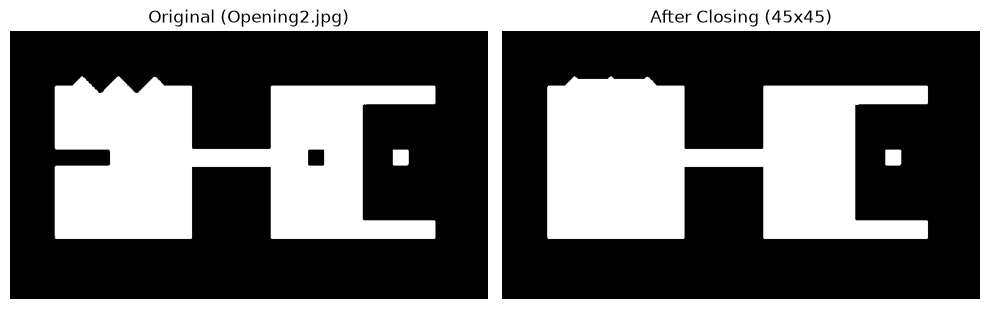

In [5]:
# Morphological Closing and Boundary Extraction Examples
img_op2 = cv2.imread('Opening2.jpg', 0)
_, bin_op2 = cv2.threshold(img_op2, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
closing = cv2.morphologyEx(bin_op2, cv2.MORPH_CLOSE, np.ones((45, 45), np.uint8))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1), plt.imshow(bin_op2, 'gray'), plt.title('Original (Opening2.jpg)'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(closing, 'gray'), plt.title('After Closing (45x45)'), plt.axis('off')
plt.tight_layout()
plt.show()

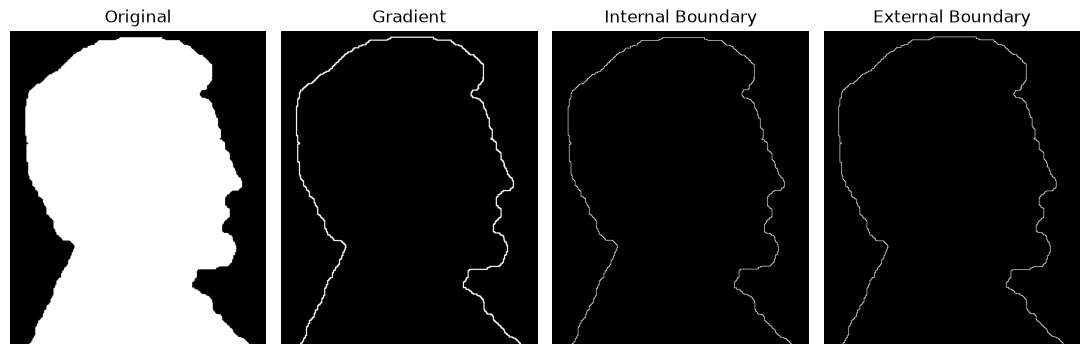

In [6]:
# Boundary Extraction (Gradient, Internal, External)
img_be = cv2.imread('BoundaryExtraction.jpg', 0)
_, bin_be = cv2.threshold(img_be, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
k3 = np.ones((3, 3), np.uint8)
gradient = cv2.morphologyEx(bin_be, cv2.MORPH_GRADIENT, k3)
internal = cv2.subtract(bin_be, cv2.erode(bin_be, k3))
external = cv2.subtract(cv2.dilate(bin_be, k3), bin_be)

plt.figure(figsize=(11, 3.5))
for i, (im, title) in enumerate(zip([bin_be, gradient, internal, external], ['Original', 'Gradient', 'Internal Boundary', 'External Boundary'])):
    plt.subplot(1, 4, i+1), plt.imshow(im, 'gray'), plt.title(title), plt.axis('off')
plt.tight_layout()
plt.show()

---
## **Task 1: Apply Morphological Operations to a New Image (`Balls.png`)**


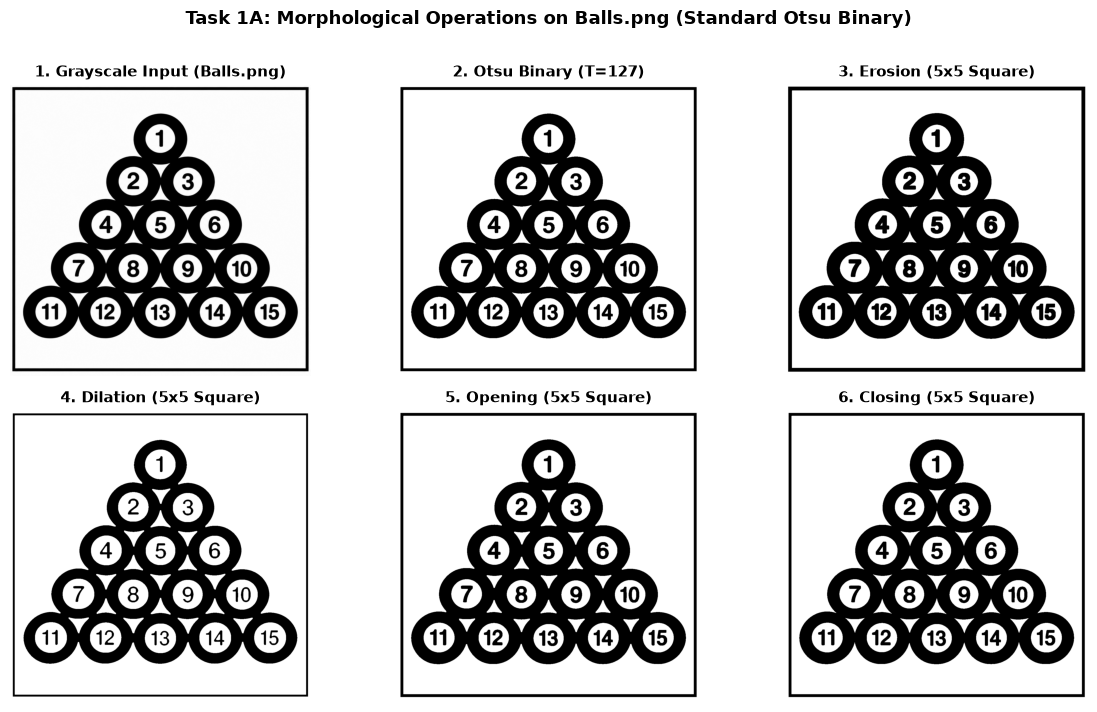

In [7]:
# Task 1A: Morphological Operations on Balls.png (Standard Otsu Binary)
img_balls = cv2.imread('Balls.png', 0)
otsu_thresh, bin_balls = cv2.threshold(img_balls, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Define a 5x5 square structuring element
kernel_5x5 = np.ones((5, 5), np.uint8)

# Apply the 4 required morphological operations
balls_eroded = cv2.erode(bin_balls, kernel_5x5, iterations=1)
balls_dilated = cv2.dilate(bin_balls, kernel_5x5, iterations=1)
balls_opened = cv2.morphologyEx(bin_balls, cv2.MORPH_OPEN, kernel_5x5)
balls_closed = cv2.morphologyEx(bin_balls, cv2.MORPH_CLOSE, kernel_5x5)

# Display original and processed images
titles = [
    '1. Grayscale Input (Balls.png)',
    f'2. Otsu Binary (T={int(otsu_thresh)})',
    '3. Erosion (5x5 Square)',
    '4. Dilation (5x5 Square)',
    '5. Opening (5x5 Square)',
    '6. Closing (5x5 Square)'
]
images = [img_balls, bin_balls, balls_eroded, balls_dilated, balls_opened, balls_closed]

plt.figure(figsize=(12, 7))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i], fontsize=10.5, fontweight='bold')
    plt.axis('off')
plt.suptitle('Task 1A: Morphological Operations on Balls.png (Standard Otsu Binary)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

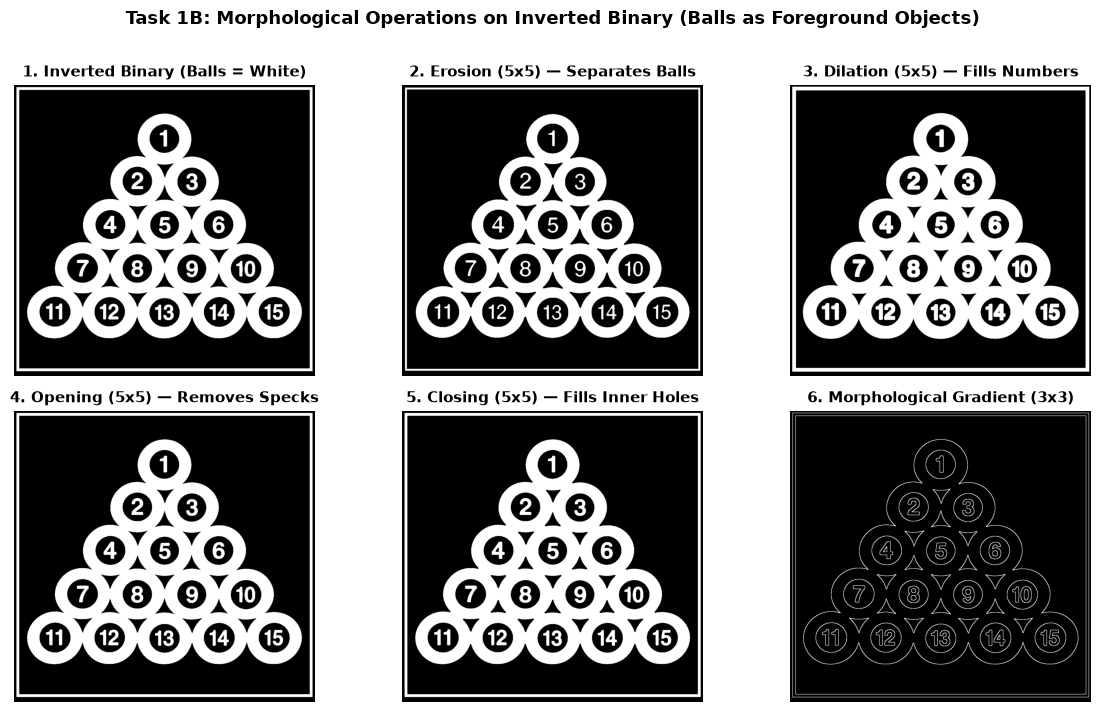

In [8]:
# Task 1B: Morphological Operations on Inverted Binary (Balls as White Foreground Objects)
_, bin_balls_inv = cv2.threshold(img_balls, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

balls_inv_eroded = cv2.erode(bin_balls_inv, kernel_5x5, iterations=1)
balls_inv_dilated = cv2.dilate(bin_balls_inv, kernel_5x5, iterations=1)
balls_inv_opened = cv2.morphologyEx(bin_balls_inv, cv2.MORPH_OPEN, kernel_5x5)
balls_inv_closed = cv2.morphologyEx(bin_balls_inv, cv2.MORPH_CLOSE, kernel_5x5)
balls_grad = cv2.morphologyEx(bin_balls_inv, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8))

inv_titles = [
    '1. Inverted Binary (Balls = White)',
    '2. Erosion (5x5) — Separates Balls',
    '3. Dilation (5x5) — Fills Numbers',
    '4. Opening (5x5) — Removes Specks',
    '5. Closing (5x5) — Fills Inner Holes',
    '6. Morphological Gradient (3x3)'
]
inv_images = [bin_balls_inv, balls_inv_eroded, balls_inv_dilated, balls_inv_opened, balls_inv_closed, balls_grad]

plt.figure(figsize=(12, 7))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(inv_images[i], 'gray')
    plt.title(inv_titles[i], fontsize=10.5, fontweight='bold')
    plt.axis('off')
plt.suptitle('Task 1B: Morphological Operations on Inverted Binary (Balls as Foreground Objects)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## **Task 2: Experiment with Structuring Elements (Shapes & Kernel Sizes)**


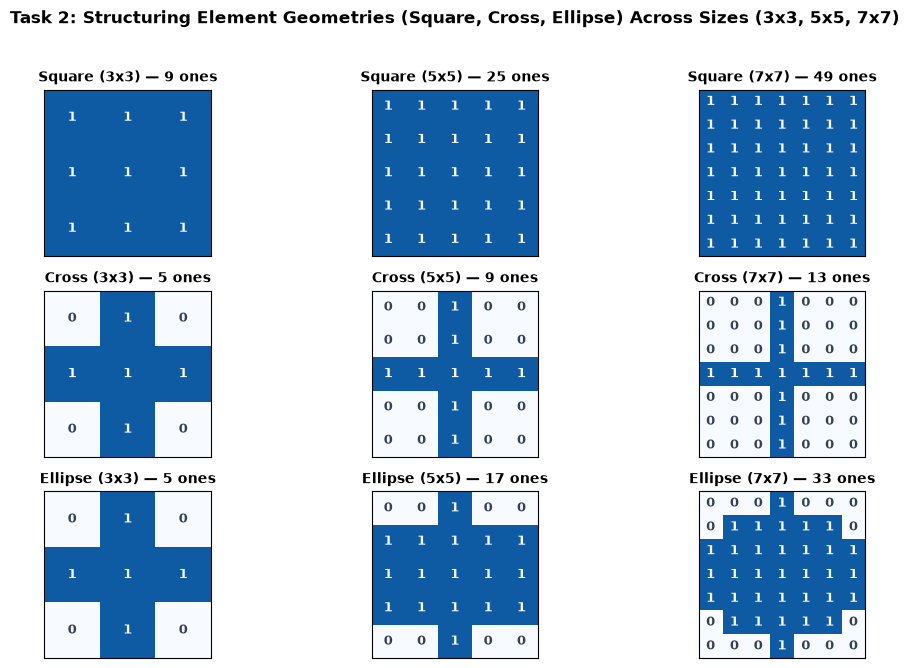

In [9]:
# Visualize the Structuring Element Kernels across Shapes (Square, Cross, Ellipse) and Sizes (3x3, 5x5, 7x7)
shapes = {
    'Square (MORPH_RECT)': cv2.MORPH_RECT,
    'Cross (MORPH_CROSS)': cv2.MORPH_CROSS,
    'Ellipse (MORPH_ELLIPSE)': cv2.MORPH_ELLIPSE
}
sizes = [3, 5, 7]

plt.figure(figsize=(11, 6.5))
plot_idx = 1
for s_name, s_flag in shapes.items():
    for k_size in sizes:
        k_mat = cv2.getStructuringElement(s_flag, (k_size, k_size))
        ax = plt.subplot(3, 3, plot_idx)
        ax.imshow(k_mat, cmap='Blues', vmin=0, vmax=1.2)
        for y in range(k_size):
            for x in range(k_size):
                ax.text(x, y, str(k_mat[y, x]), ha='center', va='center',
                        color='white' if k_mat[y, x] == 1 else '#334155', fontsize=9, fontweight='bold')
        ax.set_title(f"{s_name.split(' ')[0]} ({k_size}x{k_size}) — {int(np.sum(k_mat))} ones", fontsize=10, fontweight='bold')
        ax.set_xticks([]), ax.set_yticks([])
        plot_idx += 1
plt.suptitle('Task 2: Structuring Element Geometries (Square, Cross, Ellipse) Across Sizes (3x3, 5x5, 7x7)', fontsize=12.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

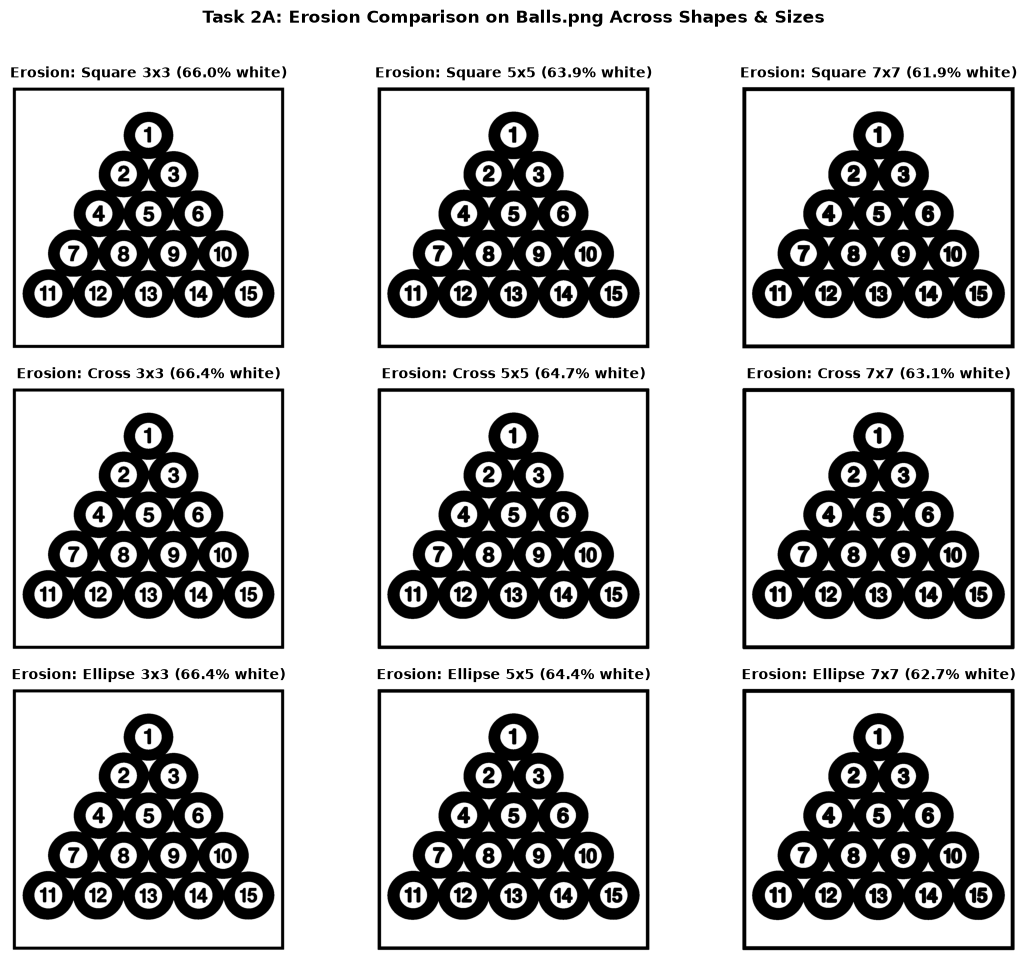

In [10]:
# Task 2A: Apply Erosion using Square, Cross, and Ellipse kernels of sizes 3x3, 5x5, and 7x7
plt.figure(figsize=(11.5, 9.5))
plot_idx = 1
total_px = bin_balls.size

for s_name, s_flag in shapes.items():
    short_shape = s_name.split(' ')[0]
    for k_size in sizes:
        kernel = cv2.getStructuringElement(s_flag, (k_size, k_size))
        eroded = cv2.erode(bin_balls, kernel, iterations=1)
        white_pct = np.sum(eroded == 255) / total_px * 100
        
        plt.subplot(3, 3, plot_idx)
        plt.imshow(eroded, 'gray')
        plt.title(f'Erosion: {short_shape} {k_size}x{k_size} ({white_pct:.1f}% white)', fontsize=10, fontweight='bold')
        plt.axis('off')
        plot_idx += 1

plt.suptitle('Task 2A: Erosion Comparison on Balls.png Across Shapes & Sizes', fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

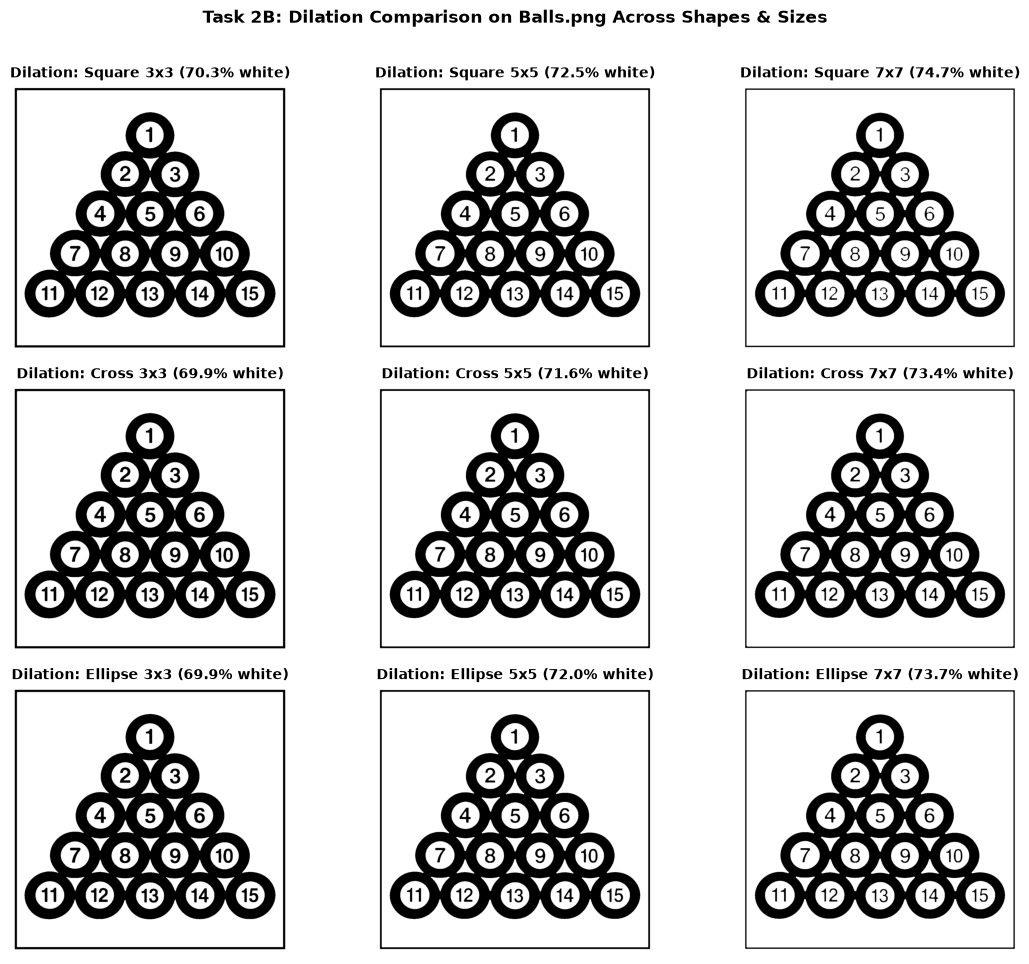

In [11]:
# Task 2B: Apply Dilation using Square, Cross, and Ellipse kernels of sizes 3x3, 5x5, and 7x7
plt.figure(figsize=(11.5, 9.5))
plot_idx = 1

for s_name, s_flag in shapes.items():
    short_shape = s_name.split(' ')[0]
    for k_size in sizes:
        kernel = cv2.getStructuringElement(s_flag, (k_size, k_size))
        dilated = cv2.dilate(bin_balls, kernel, iterations=1)
        white_pct = np.sum(dilated == 255) / total_px * 100
        
        plt.subplot(3, 3, plot_idx)
        plt.imshow(dilated, 'gray')
        plt.title(f'Dilation: {short_shape} {k_size}x{k_size} ({white_pct:.1f}% white)', fontsize=10, fontweight='bold')
        plt.axis('off')
        plot_idx += 1

plt.suptitle('Task 2B: Dilation Comparison on Balls.png Across Shapes & Sizes', fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

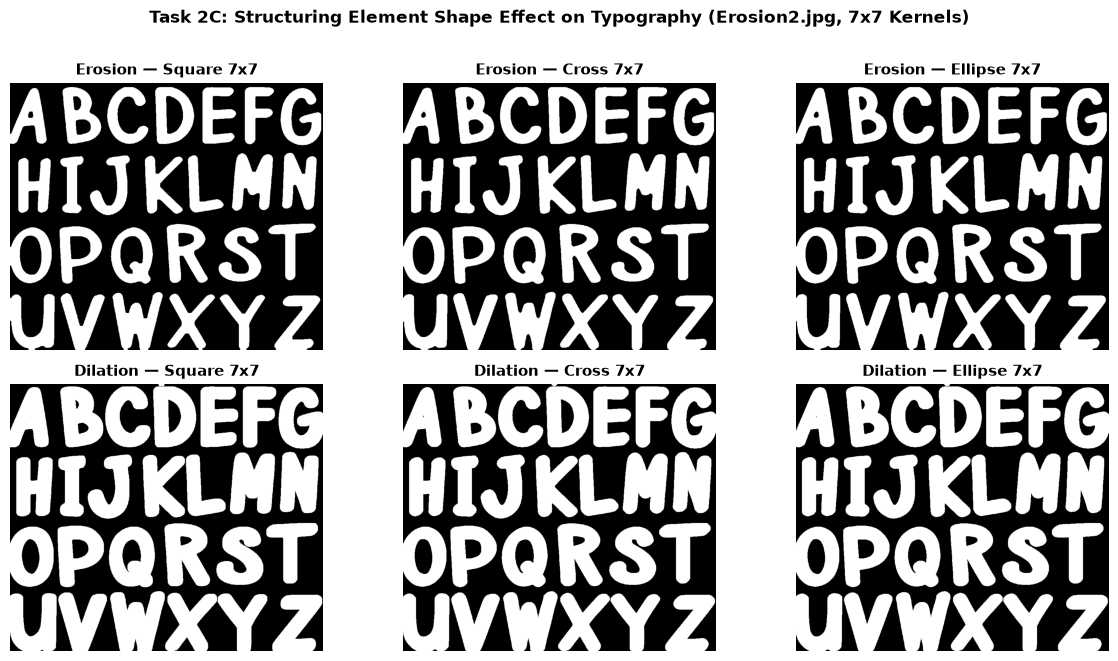

In [12]:
# Task 2C: Supplementary Shape Comparison on Typography (Erosion2.jpg) using 7x7 Kernels
img_er2 = cv2.imread('Erosion2.jpg', 0)
_, bin_er2 = cv2.threshold(img_er2, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

plt.figure(figsize=(12, 6.5))
sub_idx = 1
for op_name, op_fn in [('Erosion', cv2.erode), ('Dilation', cv2.dilate)]:
    for s_name, s_flag in shapes.items():
        short_shape = s_name.split(' ')[0]
        k7_shape = cv2.getStructuringElement(s_flag, (7, 7))
        res_er2 = op_fn(bin_er2, k7_shape, iterations=1)
        plt.subplot(2, 3, sub_idx)
        plt.imshow(res_er2, 'gray')
        plt.title(f'{op_name} — {short_shape} 7x7', fontsize=10.5, fontweight='bold')
        plt.axis('off')
        sub_idx += 1

plt.suptitle('Task 2C: Structuring Element Shape Effect on Typography (Erosion2.jpg, 7x7 Kernels)', fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()